# Lab 2: County School Installation Analysis

## 1. Objective and dataset

This notebook preprocesses the supplied county school data, identifies unusual county profiles, and explores clusters of counties with similar installation characteristics. The analysis is descriptive and uses no external data.

**Environment.** From the project root, install `requirements.txt` in a local `.venv` and run this notebook with that environment. The relative data path below therefore works from the repository root.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

environment = pd.Series({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
}, name="version")
display(environment.to_frame())

,version
Python,3.14.6
pandas,3.1.0
NumPy,2.5.4
matplotlib,3.11.2
seaborn,0.13.2
scikit-learn,1.9.1


In [2]:
data_path = Path("data") / "Country Schools.csv"
assert data_path.exists(), f"Dataset not found: {data_path}"
raw_data = pd.read_csv(data_path)

print(f"Raw dimensions: {raw_data.shape[0]} rows × {raw_data.shape[1]} columns")
display(raw_data.head())
inspection = pd.DataFrame({
    "data type": raw_data.dtypes.astype(str),
    "missing": raw_data.isna().sum(),
    "unique non-missing": raw_data.nunique(dropna=True),
})
display(inspection)
print(f"Fully duplicated rows: {raw_data.duplicated().sum()}")
print(f"Duplicate non-missing county labels: {raw_data.loc[raw_data['SNO'].notna(), 'SNO'].duplicated().sum()}")

Raw dimensions: 50 rows × 8 columns


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


,data type,missing,unique non-missing
SNO,str,2,48
TOTALSCHOOLS,float64,2,48
TotalSchoolsInstalled,float64,2,48
SchoolsPending,float64,2,47
PercentageInstalled,str,2,48
InstalledLDDs,float64,2,48
InstalledTDDs,float64,2,48
FID,int64,0,50


Fully duplicated rows: 0
Duplicate non-missing county labels: 0


## 2. Data inspection and preprocessing

`SNO` contains county labels, while `FID` is an identifier rather than a modelling feature. The `TOTAL` record is retained only for reconciliation. Records with no content outside `FID` are identified from their content and excluded. County labels are stripped, internal whitespace is collapsed, and capitalization is standardized. Percentages remain on their documented 0–100 scale.

In [3]:
content_columns = [column for column in raw_data.columns if column != "FID"]
id_only_mask = raw_data[content_columns].isna().all(axis=1)
normalized_source_names = raw_data["SNO"].astype("string").str.strip().str.upper()
total_mask = normalized_source_names.eq("TOTAL").fillna(False)

display(Markdown("**ID-only source records (excluded):**"))
display(raw_data.loc[id_only_mask, ["SNO", "FID"]])

readable_names = {
    "SNO": "county",
    "TOTALSCHOOLS": "total_schools",
    "TotalSchoolsInstalled": "installed_schools",
    "SchoolsPending": "pending_schools",
    "PercentageInstalled": "installation_pct",
    "InstalledLDDs": "installed_ldds",
    "InstalledTDDs": "installed_tdds",
    "FID": "fid",
}
cleanable = raw_data.loc[~id_only_mask].rename(columns=readable_names).copy()
cleanable["county"] = (cleanable["county"].astype("string").str.strip()
                         .str.replace(r"\s+", " ", regex=True).str.title())
count_columns = ["total_schools", "installed_schools", "pending_schools",
                 "installed_ldds", "installed_tdds"]
for column in count_columns + ["fid"]:
    cleanable[column] = pd.to_numeric(cleanable[column], errors="coerce")
cleanable["installation_pct"] = pd.to_numeric(
    cleanable["installation_pct"].astype("string").str.replace("%", "", regex=False),
    errors="coerce",
)

total_row = cleanable.loc[cleanable["county"].str.upper().eq("TOTAL")].iloc[0]
county_data = cleanable.loc[~cleanable["county"].str.upper().eq("TOTAL")].copy()
numeric_columns = count_columns + ["installation_pct"]

cleaning_summary = pd.Series({
    "raw rows": len(raw_data),
    "TOTAL rows excluded from modelling": int(total_mask.sum()),
    "ID-only rows excluded": int(id_only_mask.sum()),
    "county rows after cleaning": len(county_data),
    "missing/invalid numeric values after conversion": int(county_data[numeric_columns].isna().sum().sum()),
}, name="count")
display(cleaning_summary.to_frame())
display(county_data.head())

**ID-only source records (excluded):**

,SNO,FID
48,NaN,49
49,NaN,50


,count
raw rows,50
TOTAL rows excluded from modelling,1
ID-only rows excluded,2
county rows after cleaning,47
missing/invalid numeric values after conversion,0


,county,total_schools,installed_schools,pending_schools,installation_pct,installed_ldds,installed_tdds,fid
0,Turkana,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,Homa Bay,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,West Pokot,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,Kitui,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,Tana River,159.0,143.0,16.0,89.94,7415.0,286.0,5


In [4]:
calculated_pct = county_data["installed_schools"] / county_data["total_schools"] * 100
totals_check = pd.DataFrame({
    "calculated from counties": county_data[count_columns].sum(),
    "supplied TOTAL": total_row[count_columns].astype(float),
})
totals_check["difference"] = (totals_check["calculated from counties"]
                              - totals_check["supplied TOTAL"])
validation = pd.Series({
    "unique county names": county_data["county"].is_unique,
    "all counts nonnegative": county_data[count_columns].ge(0).all().all(),
    "percentages within 0–100": county_data["installation_pct"].between(0, 100).all(),
    "installed + pending = total for every county": (
        county_data["installed_schools"] + county_data["pending_schools"]
        == county_data["total_schools"]
    ).all(),
    "reported percentage agrees within 0.01 points": (
        county_data["installation_pct"].sub(calculated_pct).abs() <= 0.01
    ).all(),
    "county count totals equal supplied TOTAL row": totals_check["difference"].eq(0).all(),
    "installed TDDs = 2 × installed schools (counties)": (
        county_data["installed_tdds"] == 2 * county_data["installed_schools"]
    ).all(),
    "installed TDDs = 2 × installed schools (TOTAL)": (
        total_row["installed_tdds"] == 2 * total_row["installed_schools"]
    ),
}, name="result")
display(validation.to_frame())
display(Markdown("**Count reconciliation with the supplied TOTAL row:**"))
display(totals_check)
print(f"Maximum absolute percentage difference: {county_data['installation_pct'].sub(calculated_pct).abs().max():.4f} percentage points")
print(f"Unique county names ({county_data['county'].nunique()}): {', '.join(sorted(county_data['county']))}")

assert len(county_data) == 47
assert county_data["county"].is_unique
assert county_data[numeric_columns].notna().all().all()

,result
unique county names,True
all counts nonnegative,True
percentages within 0–100,True
installed + pending = total for every county,True
reported percentage agrees within 0.01 points,True
county count totals equal supplied TOTAL row,True
installed TDDs = 2 × installed schools (counties),True
installed TDDs = 2 × installed schools (TOTAL),True


**Count reconciliation with the supplied TOTAL row:**

,calculated from counties,supplied TOTAL,difference
total_schools,21729.0,21729.0,0.0
installed_schools,14629.0,14629.0,0.0
pending_schools,7100.0,7100.0,0.0
installed_ldds,723618.0,723618.0,0.0
installed_tdds,29258.0,29258.0,0.0


Maximum absolute percentage difference: 0.0050 percentage points
Unique county names (47): Baringo, Bomet, Bungoma, Busia, Elgeyo, Embu, Garissa, Homa Bay, Isiolo, Kajiado, Kakamega, Kericho, Kiambu, Kilifi, Kirinyaga, Kisii, Kisumu, Kitui, Kwale, Laikipia, Lamu, Machakos, Makueni, Mandera, Marsabit, Meru, Migori, Mombasa, Murang'A, Nairobi, Nakuru, Nandi, Narok, Nyamira, Nyandarua, Nyeri, Samburu, Siaya, Taita Taveta, Tana River, Tharaka Nithi, Trans Nzoia, Turkana, Uasin Gishu, Vihiga, Wajir, West Pokot


All 47 county records have valid converted values and unique normalized names. The source spelling `ElGEYO ` illustrates the capitalization and whitespace issue corrected during normalization. The consistency checks reveal no count or percentage discrepancies, so no values are imputed or repaired. `FID` and the supplied aggregate remain outside modelling.

## 3. Exploratory analysis and feature preparation

Three interpretable features are used: total schools, installation percentage, and installed LDDs per installed school. The ratio is sensitive when few schools have installations, so it is interpreted alongside the installation count. County names and `FID` are identifiers. Related totals, pending/installed counts, and percentages are not all included because doing so would give the same underlying installation scale disproportionate weight.

Zero installed-school denominators: 0


,count,mean,std,min,25%,50%,75%,max
total_schools,47.0,462.319149,254.204395,93.0,251.5,413.0,633.5,1238.0
installation_pct,47.0,63.919149,25.847635,4.55,50.305,65.0,84.935,96.93
installed_ldds_per_installed_school,47.0,53.000571,19.533228,25.733591,38.243632,47.738462,61.453657,116.222222


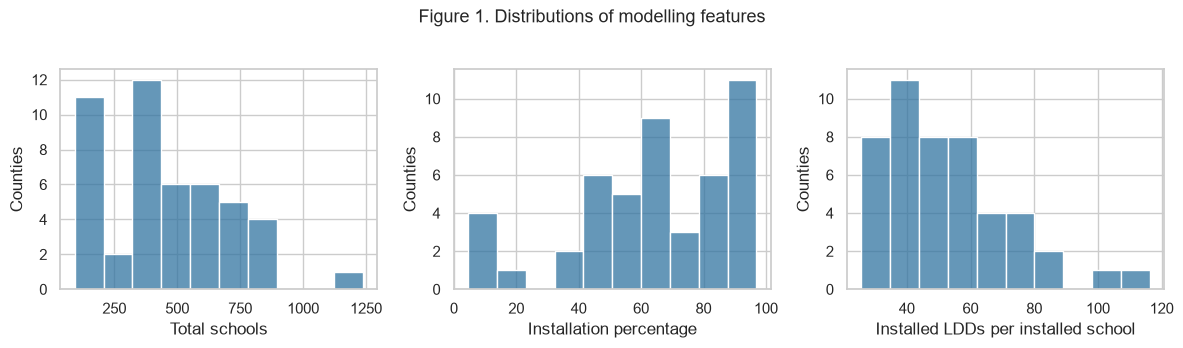

Feature scales differ substantially, so the three features are standardized to mean 0 and standard deviation 1 before anomaly detection and clustering. Tables and substantive interpretations remain in original units.

In [5]:
zero_denominators = county_data["installed_schools"].eq(0)
print(f"Zero installed-school denominators: {zero_denominators.sum()}")
county_data["installed_ldds_per_installed_school"] = (
    county_data["installed_ldds"] / county_data["installed_schools"]
)
feature_columns = ["total_schools", "installation_pct",
                   "installed_ldds_per_installed_school"]
feature_labels = {
    "total_schools": "Total schools",
    "installation_pct": "Installation percentage",
    "installed_ldds_per_installed_school": "Installed LDDs per installed school",
}
features = county_data[feature_columns].copy()
assert np.isfinite(features.to_numpy(dtype=float)).all()
display(features.describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for axis, feature in zip(axes, feature_columns):
    sns.histplot(data=county_data, x=feature, bins=10, color="#3274A1", edgecolor="white", ax=axis)
    axis.set_xlabel(feature_labels[feature])
    axis.set_ylabel("Counties")
fig.suptitle("Figure 1. Distributions of modelling features", y=1.02, fontsize=13)
fig.tight_layout()
plt.show()

scaler = StandardScaler()
standardized_features = scaler.fit_transform(features)
assert np.isfinite(standardized_features).all()
display(Markdown(
    "Feature scales differ substantially, so the three features are standardized to mean 0 and standard deviation 1 "
    "before anomaly detection and clustering. Tables and substantive interpretations remain in original units."
))

## 4. Anomaly detection

The IQR baseline flags a county when any original-unit feature falls outside the usual 1.5 × IQR fences. Isolation Forest detects unusual multivariate combinations after standardization. Its score is defined here as the negative of `score_samples`, so larger values always mean a more unusual observation.

In [6]:
from sklearn.ensemble import IsolationForest

first_quartile = features.quantile(0.25)
third_quartile = features.quantile(0.75)
iqr = third_quartile - first_quartile
lower_fence = first_quartile - 1.5 * iqr
upper_fence = third_quartile + 1.5 * iqr
iqr_feature_flags = features.lt(lower_fence) | features.gt(upper_fence)
county_data["iqr_flag"] = iqr_feature_flags.any(axis=1)

isolation_forest = IsolationForest(
    n_estimators=200, contamination=0.10, random_state=42
)
isolation_forest.fit(standardized_features)
county_data["anomaly_score"] = -isolation_forest.score_samples(standardized_features)
county_data["isolation_forest_flag"] = isolation_forest.predict(standardized_features) == -1

ranked_anomalies = county_data[["county"] + feature_columns + [
    "anomaly_score", "iqr_flag", "isolation_forest_flag"
]].sort_values("anomaly_score", ascending=False).reset_index(drop=True)
ranked_anomalies.index = ranked_anomalies.index + 1
ranked_anomalies.index.name = "rank"
display(ranked_anomalies.head(12).rename(columns=feature_labels).round(3))

assert len(ranked_anomalies) == len(county_data)
assert county_data["anomaly_score"].notna().all()
assert county_data["isolation_forest_flag"].shape[0] == 47

,county,Total schools,Installation percentage,Installed LDDs per installed school,anomaly_score,iqr_flag,isolation_forest_flag
rank,,,,,,,
1,Kitui,1238.0,96.93,35.135,0.665,True,True
2,Mandera,198.0,4.55,116.222,0.645,True,True
3,Turkana,358.0,10.34,101.189,0.626,True,True
4,Marsabit,138.0,5.8,75.750,0.560,False,True
5,Wajir,211.0,5.21,77.727,0.548,False,True
6,Kakamega,880.0,65.0,77.514,0.547,False,False
7,Garissa,163.0,19.02,50.613,0.544,False,False
8,Lamu,93.0,95.7,34.640,0.538,False,False
9,Nyeri,392.0,37.5,26.469,0.533,False,False


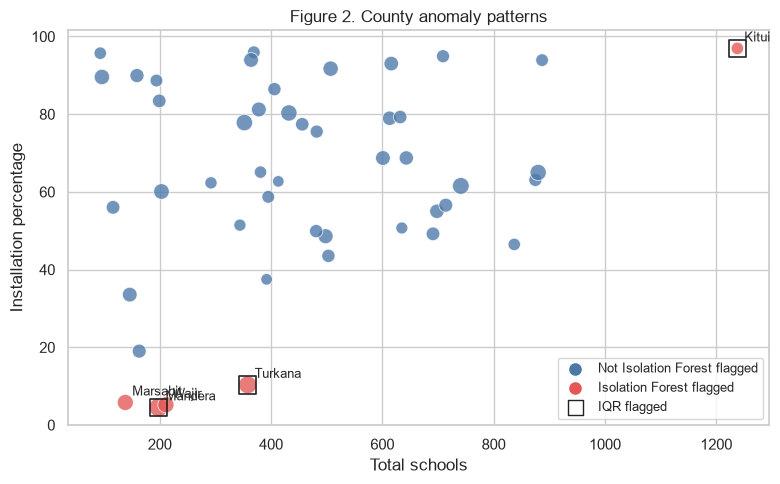

In [7]:
figure, axis = plt.subplots(figsize=(8, 5))
point_colors = county_data["isolation_forest_flag"].map({False: "#4C78A8", True: "#E45756"})
point_sizes = 35 + 1.3 * county_data["installed_ldds_per_installed_school"]
axis.scatter(county_data["total_schools"], county_data["installation_pct"],
             s=point_sizes, c=point_colors, alpha=0.78, edgecolor="white", linewidth=0.6)
iqr_counties = county_data.loc[county_data["iqr_flag"]]
axis.scatter(iqr_counties["total_schools"], iqr_counties["installation_pct"],
             s=160, facecolors="none", edgecolors="#222222", linewidth=1.2, marker="s")
for _, row in ranked_anomalies.head(5).iterrows():
    axis.annotate(row["county"], (row["total_schools"], row["installation_pct"]),
                  xytext=(5, 5), textcoords="offset points", fontsize=9)
axis.scatter([], [], s=65, c="#4C78A8", label="Not Isolation Forest flagged")
axis.scatter([], [], s=65, c="#E45756", label="Isolation Forest flagged")
axis.scatter([], [], s=110, facecolors="none", edgecolors="#222222", marker="s", label="IQR flagged")
axis.set(xlabel="Total schools", ylabel="Installation percentage",
         title="Figure 2. County anomaly patterns")
axis.legend(frameon=True, fontsize=9)
figure.tight_layout()
plt.show()

In [8]:
leading_names = ", ".join(ranked_anomalies.head(5)["county"])
iqr_names = ", ".join(county_data.loc[county_data["iqr_flag"], "county"])
if_only_names = ", ".join(county_data.loc[
    county_data["isolation_forest_flag"] & ~county_data["iqr_flag"], "county"
])
display(Markdown(
    f"**Interpretation.** The five leading Isolation Forest observations are {leading_names}. "
    f"The IQR baseline flags {iqr_names}. Kitui is unusual mainly for its very large school count combined with "
    f"high installation, while Mandera and Turkana combine low installation percentages with high LDD ratios. "
    f"Isolation Forest additionally flags {if_only_names}, whose joint profiles are unusual although no single feature "
    f"crosses an IQR fence. The methods therefore agree on three counties and differ on two multivariate cases.\n\n"
    "The 10% contamination setting is an exploratory threshold assumption, not a measured anomaly prevalence. "
    "Unusual counties are not automatically data errors. With no true anomaly labels, accuracy, precision, recall, "
    "and F1 are not applicable."
))

**Interpretation.** The five leading Isolation Forest observations are Kitui, Mandera, Turkana, Marsabit, Wajir. The IQR baseline flags Turkana, Kitui, Mandera. Kitui is unusual mainly for its very large school count combined with high installation, while Mandera and Turkana combine low installation percentages with high LDD ratios. Isolation Forest additionally flags Wajir, Marsabit, whose joint profiles are unusual although no single feature crosses an IQR fence. The methods therefore agree on three counties and differ on two multivariate cases.

The 10% contamination setting is an exploratory threshold assumption, not a measured anomaly prevalence. Unusual counties are not automatically data errors. With no true anomaly labels, accuracy, precision, recall, and F1 are not applicable.

## 5. Cluster analysis

K-means is compared for `k=2` through `k=6` on all three standardized features. Lower inertia and Davies–Bouldin values are preferable; a higher silhouette score indicates clearer separation. Inertia necessarily decreases as k rises, so the other metrics and interpretability also guide selection. Valid anomaly observations remain in the analysis.

In [9]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score

k_results = []
fitted_kmeans = {}
for cluster_count in range(2, 7):
    model = KMeans(n_clusters=cluster_count, random_state=42, n_init=20)
    labels = model.fit_predict(standardized_features)
    fitted_kmeans[cluster_count] = model
    sizes = pd.Series(labels).value_counts().sort_index()
    k_results.append({
        "k": cluster_count,
        "inertia": model.inertia_,
        "silhouette score": silhouette_score(standardized_features, labels),
        "Davies–Bouldin index": davies_bouldin_score(standardized_features, labels),
        "cluster sizes": ", ".join(f"C{index}: {size}" for index, size in sizes.items()),
    })
k_comparison = pd.DataFrame(k_results).set_index("k")
display(k_comparison.round(3))

,inertia,silhouette score,Davies–Bouldin index,cluster sizes
k,,,,
2,92.952,0.444,0.812,"C0: 41, C1: 6"
3,66.782,0.281,1.157,"C0: 16, C1: 6, C2: 25"
4,51.284,0.298,0.999,"C0: 4, C1: 15, C2: 15, C3: 13"
5,43.103,0.275,1.050,"C0: 10, C1: 12, C2: 4, C3: 11, C4: 10"
6,35.966,0.300,0.939,"C0: 4, C1: 14, C2: 10, C3: 4, C4: 5, C5: 10"


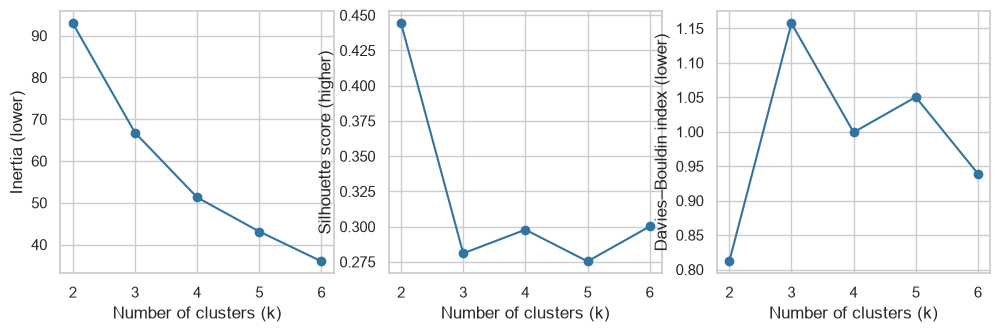

In [10]:
figure, axes = plt.subplots(1, 3, figsize=(12, 3.4))
diagnostics = [
    ("inertia", "Inertia (lower)"),
    ("silhouette score", "Silhouette score (higher)"),
    ("Davies–Bouldin index", "Davies–Bouldin index (lower)"),
]
for axis, (metric, label) in zip(axes, diagnostics):
    axis.plot(k_comparison.index, k_comparison[metric], marker="o", color="#3274A1")
    axis.set(xlabel="Number of clusters (k)", ylabel=label, xticks=range(2, 7))
fig.suptitle("Figure 3. K-means selection diagnostics", y=1.02, fontsize=13)
fig.tight_layout()
plt.show()

In [11]:
selected_k = 2
selected_model = fitted_kmeans[selected_k]
county_data["cluster"] = selected_model.labels_
cluster_means = county_data.groupby("cluster")[feature_columns].mean()
low_installation_cluster = cluster_means["installation_pct"].idxmin()
cluster_name_map = {
    cluster: ("Low-installation, high-ratio" if cluster == low_installation_cluster
              else "Broad installation profile")
    for cluster in cluster_means.index
}
county_data["cluster_name"] = county_data["cluster"].map(cluster_name_map)

cluster_profiles = county_data.groupby(["cluster", "cluster_name"]).agg(
    counties=("county", "size"),
    mean_total_schools=("total_schools", "mean"),
    mean_installation_pct=("installation_pct", "mean"),
    mean_ldds_per_installed_school=("installed_ldds_per_installed_school", "mean"),
).round(2)
display(Markdown("**Selected cluster sizes and original-unit profiles:**"))
display(cluster_profiles)

membership = county_data[["county", "cluster", "cluster_name"]].sort_values(
    ["cluster", "county"]
).reset_index(drop=True)
display(Markdown("**Complete county membership:**"))
display(membership)

assert county_data["cluster"].notna().all()
assert len(membership) == 47

**Selected cluster sizes and original-unit profiles:**

,,counties,mean_total_schools,mean_installation_pct,mean_ldds_per_installed_school
cluster,cluster_name,,,,
0,Broad installation profile,41,500.37,71.36,49.04
1,"Low-installation, high-ratio",6,202.33,13.08,80.08


**Complete county membership:**

,county,cluster,cluster_name
0,Baringo,0,Broad installation profile
1,Bomet,0,Broad installation profile
2,Bungoma,0,Broad installation profile
3,Busia,0,Broad installation profile
4,Elgeyo,0,Broad installation profile
5,Embu,0,Broad installation profile
6,Homa Bay,0,Broad installation profile
7,Isiolo,0,Broad installation profile
8,Kajiado,0,Broad installation profile
9,Kakamega,0,Broad installation profile


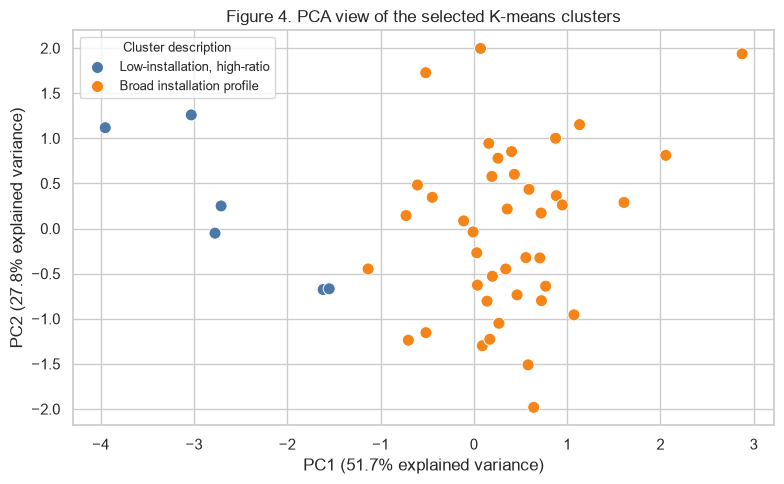

PCA is used only for this two-dimensional visualization. K-means uses all three standardized features.

In [12]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(standardized_features)
pca_frame = pd.DataFrame(principal_components, columns=["PC1", "PC2"])
pca_frame["cluster_name"] = county_data["cluster_name"].to_numpy()
pca_frame["county"] = county_data["county"].to_numpy()

figure, axis = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue="cluster_name",
                palette=["#4C78A8", "#F58518"], s=75, edgecolor="white", ax=axis)
axis.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% explained variance)")
axis.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% explained variance)")
axis.set_title("Figure 4. PCA view of the selected K-means clusters")
axis.legend(title="Cluster description", fontsize=9, title_fontsize=9)
figure.tight_layout()
plt.show()
display(Markdown(
    "PCA is used only for this two-dimensional visualization. K-means uses all three standardized features."
))

In [13]:
broad_profile = cluster_profiles.xs("Broad installation profile", level="cluster_name").iloc[0]
low_profile = cluster_profiles.xs("Low-installation, high-ratio", level="cluster_name").iloc[0]
low_members = ", ".join(membership.loc[
    membership["cluster_name"].eq("Low-installation, high-ratio"), "county"
])
display(Markdown(
    f"**Selection and interpretation.** `k=2` has the highest silhouette score "
    f"({k_comparison.loc[2, 'silhouette score']:.3f}) and lowest Davies–Bouldin index "
    f"({k_comparison.loc[2, 'Davies–Bouldin index']:.3f}) among the tested solutions. It is also readily "
    f"interpretable, although the smaller cluster has only {int(low_profile['counties'])} counties. The broad "
    f"installation cluster contains {int(broad_profile['counties'])} counties and averages "
    f"{broad_profile['mean_installation_pct']:.2f}% installed. The low-installation, high-ratio cluster contains "
    f"{low_members}; it averages {low_profile['mean_installation_pct']:.2f}% installed and "
    f"{low_profile['mean_ldds_per_installed_school']:.2f} LDDs per installed school. Cluster numbers are "
    "identifiers, not rankings. Separation is useful descriptively but should not be treated as a fixed taxonomy."
))

**Selection and interpretation.** `k=2` has the highest silhouette score (0.444) and lowest Davies–Bouldin index (0.812) among the tested solutions. It is also readily interpretable, although the smaller cluster has only 6 counties. The broad installation cluster contains 41 counties and averages 71.36% installed. The low-installation, high-ratio cluster contains Garissa, Mandera, Marsabit, Samburu, Turkana, Wajir; it averages 13.08% installed and 80.08 LDDs per installed school. Cluster numbers are identifiers, not rankings. Separation is useful descriptively but should not be treated as a fixed taxonomy.